Задача 1. Данные по плей-офф НХЛ 2025/26.

Файл читаем с index_col=0, иначе получаеться 39 столбцов вместо 38 - первый столбец
это сохранённый индекс.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os

from rink import plot_rink

sns.set_theme(style='whitegrid')
pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 50)
pd.set_option('display.float_format', lambda v: '%.3f' % v)

os.makedirs('figures', exist_ok=True)
FIG = 'figures'

### 1. Читаем данные

In [3]:
events = pd.read_excel('NHL-playoffs-2026.xlsx', index_col=0)
events.shape

(29710, 38)

29710 строк и 38 столбцов, как и должно быть по условию. Значит что index_col
отработал правильно.

Глянем на первые строки в тех же столбцах что и в примере задания, чтобы
убедиться что ничего не съехало.

In [4]:
events.iloc[:10, [2, 3, 4, 9, 12]]

,Date,Away Team,Home Team,Remaining Time,Play Type
0,2026-04-19,Boston Bruins,Buffalo Sabres,20:00,period-start
1,2026-04-19,Boston Bruins,Buffalo Sabres,20:00,faceoff
2,2026-04-19,Boston Bruins,Buffalo Sabres,19:47,hit
3,2026-04-19,Boston Bruins,Buffalo Sabres,19:46,hit
4,2026-04-19,Boston Bruins,Buffalo Sabres,19:41,hit
5,2026-04-19,Boston Bruins,Buffalo Sabres,19:27,hit
6,2026-04-19,Boston Bruins,Buffalo Sabres,19:03,hit
7,2026-04-19,Boston Bruins,Buffalo Sabres,18:53,missed-shot
8,2026-04-19,Boston Bruins,Buffalo Sabres,18:48,hit
9,2026-04-19,Boston Bruins,Buffalo Sabres,18:37,missed-shot


Совпадает с п
имером построчно. Матч Бостон - Баффало от 19 апреля, начало
периода, вбрасывание, дальше силовые приёмы.

Посмотрим какие вообще бывают события и сколько их. Это пригодится дальше,
чтобы правильно отбирать типы бросков.

In [5]:
events['Play Type'].value_counts()

Play Type
hit                5621
faceoff            4995
shot-on-goal       4137
stoppage           3958
blocked-shot       2798
missed-shot        2643
giveaway           2604
penalty             804
takeaway            779
goal                486
period-start        272
period-end          272
delayed-penalty     259
game-end             82
Name: count, dtype: int64

Голов 486, бросков в створ 4137, мимо 2643, заблокированных 2798. в данных тип вбрасывания записан как faceoff, а в таблице 2 задания
он с дефисом. Ориентируемся на данные.

Сразу заготовим вратарей. В 22 записях о голах состав на льду вообще не заполнен,
это победные голы в овертаймах. Вратарь там конечно был, просто состав на последнее
событие матча не записали. Если это не поправить, в пункте 21 вылезут лишние сухие
матчи.

In [6]:
noroster = (events["# of Away Team's Players on the Ice"] == 0) & (events["# of Home Team's Players on the Ice"] == 0)
awaygoalie = events["Away Team's Goalie"].where(~noroster, events.groupby('Game ID')["Away Team's Goalie"].ffill().bfill())
homegoalie = events["Home Team's Goalie"].where(~noroster, events.groupby('Game ID')["Home Team's Goalie"].ffill().bfill())

noroster.sum()

np.int64(111)

### 2. Сводка по матчам

Итоговый счёт берём из последнего события матча, поля Cumulated накопительные.
Овертаймы считаем по максимальному периоду.

In [7]:
last = events.groupby('Game ID').tail(1).set_index('Game ID')
games = last[['Date', 'Away Team', 'Home Team']].copy()
games['Away Score'] = last['Cumulated Away Score']
games['Home Score'] = last['Cumulated Home Score']

nperiods = events.groupby('Game ID')['Period'].max()

def outcome(n):
   if n <= 3:
      return 'Final'
   if n == 4:
      return 'Final/OT'
   return 'Final/%dOT' % (n - 3)

games['Outcome'] = nperiods.map(outcome)
games.iloc[-5:, -4:]

,Home Team,Away Score,Home Score,Outcome
Game ID,,,,
2025030412,Carolina Hurricanes,3,4,Final/OT
2025030413,Vegas Golden Knights,4,5,Final/2OT
2025030414,Vegas Golden Knights,5,3,Final
2025030415,Carolina Hurricanes,2,4,Final
2025030416,Vegas Golden Knights,3,0,Final


Последние пять матчей совпали с примером из условия, включая Final/OT
и Final/2OT. Значит и счёт и овертаймы посчитались верно.

Заодно посмотрим сколько вообще было овертаймов за турнир.

In [8]:
games['Outcome'].value_counts()

Outcome
Final        60
Final/OT     18
Final/2OT     4
Name: count, dtype: int64

60 матчей закончились в основное время, 18 потребовали одного овертайма
и 4 двух. Третьего овертайма в этом плей-офф не было.

### 3. Функция gameInfo

Формат: хозяева - гости (счёт хозяев - счёт гостей, исход, дата).

In [9]:
def gameInfo(gameId):
    g = games.loc[gameId]
    return '%s - %s (%d - %d, %s, %s)' % (g['Home Team'], g['Away Team'],
        g['Home Score'], g['Away Score'], g['Outcome'], g['Date'])

print(gameInfo(games.index.min()))
print(gameInfo(games.index.max()))

Buffalo Sabres - Boston Bruins (4 - 3, Final, 2026-04-19)
Vegas Golden Knights - Carolina Hurricanes (0 - 3, Final, 2026-06-14)


### 4. Сколько голов за матч

In [10]:
games['Total Score'] = games['Away Score'] + games['Home Score']
games['Total Score'].describe()

count   82.000
mean     5.927
std      2.260
min      1.000
25%      5.000
50%      6.000
75%      7.000
max     15.000
Name: Total Score, dtype: float64

В среднем около шести шайб, половина матчей укладывается в 5-7 голов.

### 5. Гистограмма

Величина дискретная, поэтому countplot. Пустые значения 12, 13, 14 добавляем через
order, чтобы ось была сплошная.

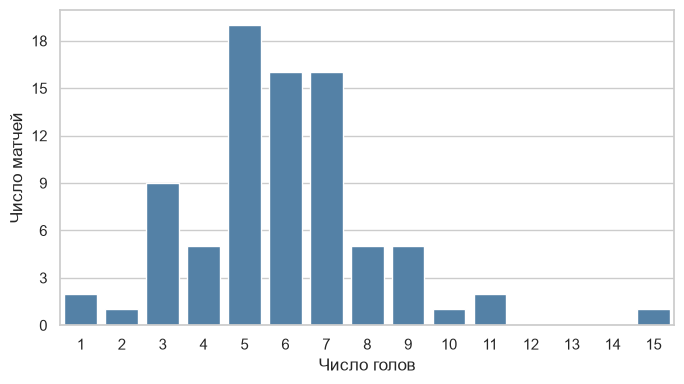

In [11]:
span = range(games['Total Score'].min(), games['Total Score'].max() + 1)

plt.figure(figsize=(7, 4))
ax = sns.countplot(x=games['Total Score'], order=span, color='steelblue')
ax.set_xlabel('Число голов')
ax.set_ylabel('Число матчей')
ax.set_yticks(range(0, 19, 3))
plt.tight_layout()
plt.savefig(FIG + '/goals_hist.pdf')
plt.savefig(FIG + '/goals_hist.png', dpi=160)
plt.show()

Распределение одновершинное с модой в пяти голах и скошено вправо. Слева обрыв
резкий, потому что ничьих не бывает и хотя бы один гол всегда есть. Справа длинный
тонкий хвост, выброс - матч Колорадо с Миннесотой на 15 шайб.

### 6. Самые и наименее результативные матчи

In [12]:
worst = games.index[games['Total Score'] == games['Total Score'].min()]
best = games.index[games['Total Score'] == games['Total Score'].max()]

print([gameInfo(i) for i in worst])
print([gameInfo(i) for i in best])

['Montréal Canadiens - Tampa Bay Lightning (0 - 1, Final/OT, 2026-05-01)', 'Philadelphia Flyers - Pittsburgh Penguins (1 - 0, Final/OT, 2026-04-29)']
['Colorado Avalanche - Minnesota Wild (9 - 6, Final, 2026-05-03)']


Обе ушли в овертайм,при 0:0 основное время часто не
выявляет побеителя.

### 7. Сколько хоккеистов участвовало

Считаем уникальные фамилии в 14 полях, по шесть полевых и вратарь у каждой команды.
Пропуски обязательно отбрасываем, иначе NaN попадёт в список как ещё один игрок
и в каждом матче получится на единицу больше.

In [14]:
oncols = ["Away Team's Player on the Ice #%d" % i for i in range(1, 7)] + ["Away Team's Goalie"] \
       + ["Home Team's Player on the Ice #%d" % i for i in range(1, 7)] + ["Home Team's Goalie"]

onice = events[['Game ID'] + oncols].melt(id_vars='Game ID', value_name='Player').dropna(subset=['Player'])
playercount = onice.groupby('Game ID')['Player'].nunique()


roster = pd.DataFrame({'Game Info': [gameInfo(i) for i in playercount.index],
                       'Player Count': playercount.values}, index=playercount.index)
roster.index.name = 'Game ID'
roster.nlargest(5, 'Player Count')

,Game Info,Player Count
Game ID,,
2025030216,"Montréal Canadiens - Buffalo Sabres (3 - 8, Fi...",40
2025030112,"Buffalo Sabres - Boston Bruins (2 - 4, Final, ...",39
2025030114,"Boston Bruins - Buffalo Sabres (1 - 6, Final, ...",39
2025030185,"Edmonton Oilers - Anaheim Ducks (4 - 1, Final,...",39
2025030215,"Buffalo Sabres - Montréal Canadiens (3 - 6, Fi...",39


Рекорд - матч Монреаль - Баффало, 40 человек. Там с каждой стороны вышло
по 20 хоккеистов, включая по два вратаря.

Отдельно замечу про идентификацию игроков. В таблице 1 эти поля описаны как фамилии,
но лежат в них полные имена. Это важно: среди 372 хоккеистов 12 пар однофамильцев
(Marcus и Nick Foligno, Elias и Hampus Lindholm, Conor и Morgan Geekie и другие).
Если резать до фамилии, эти пары склеятся, поэтому везде дальше ключом берём полную
строку с именем.

Посмотрим насколько 40 выбивается из общей картины.

In [15]:
roster['Player Count'].describe()

count   82.000
mean    38.122
std      0.365
min     38.000
25%     38.000
50%     38.000
75%     38.000
max     40.000
Name: Player Count, dtype: float64

Обычный матч даёт ровно 38 человек, медиана тоже 38. Больше бывает только там
где менялся вратарь, то есть разброс здесь не про глубину состава, а про замены
в воротах.

### 8. Расстояние до ворот

Если Home Team's Defending Sde равно left, то хозяева атакуют правые ворота (X=89),
а гости левые. При right наоборот. Пишется np.where без перебора случаев.

In [46]:
shottypes = ['shot-on-goal', 'goal', 'missed-shot']
isshot = events['Play Type'].isin(shottypes)

byhome = events['Team Making the Play'] == events['Home Team']
homeleft = events["Home Team's Defending Side"] == 'left'
targetx = np.where(byhome == homeleft, 89.0, -89.0)

x = events['X Coordinate on the Ice Rink']
y = events['Y Coordinate on the Ice Rink']
dy = np.where(y < -3, y + 3, np.where(y > 3, y - 3, 0.0))

events['Shot Length'] = np.sqrt((x - targetx) ** 2 + dy ** 2)
events.loc[~isshot, 'Shot Length'] = np.nan

events[isshot][['Game ID', 'Play Type', 'Shot Length']]

,Game ID,Play Type,Shot Length
7,2025030111,missed-shot,12.207
9,2025030111,missed-shot,12.000
12,2025030111,missed-shot,29.411
13,2025030111,shot-on-goal,62.169
19,2025030111,missed-shot,52.924
...,...,...,...
29695,2025030416,missed-shot,54.083
29696,2025030416,missed-shot,5.099
29704,2025030416,goal,46.239
29706,2025030416,missed-shot,60.926


7266 бросков, значения по строкам 7, 9, 12, 13, 19 совпали с примером задания
до третьего знака. Это хороший признак, что ориентация взята правильно.

Но совпадение по пяти строкам ещё не доказательство. Проверим что не напутали
со сторонами. Поле Play Zone размечено независимо
и оно должно согласовываться с нашим расчётом.

In [47]:
shots = events[isshot].copy()
pd.crosstab(pd.cut(shots['Shot Length'], [0, 64, 100, 200]), shots['Play Zone'])

Play Zone,Defensive,Neutral,Offensive
Shot Length,,,
"(0, 64]",0,0,6647
"(64, 100]",0,187,247
"(100, 200]",164,19,0


Всё что мы отнесли в зону атаки размечено как Offensive, совпадение полное.

In [48]:
events[isshot].groupby('Play Type')['Shot Length'].describe()

,count,mean,std,min,25%,50%,75%,max
Play Type,,,,,,,,
goal,486.000,26.006,28.090,1.000,9.000,19.013,31.941,187.216
missed-shot,2643.000,34.014,22.313,0.000,16.155,32.249,49.041,185.068
shot-on-goal,4137.000,37.405,29.990,0.000,16.643,33.377,48.508,188.215


### 9. Точные и неточные броски

Подвыборки разного размера, поэтому нужны плотности а не частоты. За это отвечает
stat='density' вместе с common_norm=False, иначе группы нормируются вместе.

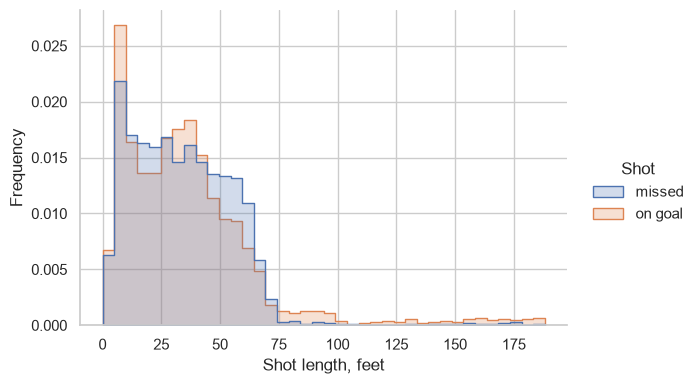

In [19]:
shots['Shot'] = np.where(shots['Play Type'] == 'missed-shot', 'missed', 'on goal')

g = sns.displot(data=shots, x='Shot Length', hue='Shot', stat='density',
                common_norm=False, binwidth=5, element='step', height=4, aspect=1.5)
g.set_axis_labels('Shot length, feet', 'Frequency')
g.savefig(FIG + '/shot_length.pdf')
g.savefig(FIG + '/shot_length.png', dpi=160)
plt.show()

Главное отличие это длинный хвост у точных бросков, у неточных его почти нет.
Посмотрим из чего он состоит.

In [20]:
far = shots[shots['Shot Length'] > 100]
print('длиннее 100 футов:', len(far))
print(far['Play Type'].value_counts())
print('точных к неточным, дальние: %.2f' % ((far['Play Type'] != 'missed-shot').sum() / (far['Play Type'] == 'missed-shot').sum()))
print('точных к неточным, все:    %.2f' % ((shots['Play Type'] != 'missed-shot').sum() / (shots['Play Type'] == 'missed-shot').sum()))

длиннее 100 футов: 183
Play Type
shot-on-goal    143
missed-shot      23
goal             17
Name: count, dtype: int64
точных к неточным, дальние: 6.96
точных к неточным, все:    1.75


В хвосте 183 броска
 и соотношение точных к неточным там 6.96 против 1.75
по всей выборке. То есть хвост почти целиком состоит из точных.

Проверим гипотеу про пустые ворота: если это они, дальние броски должны кучковаться
в концовке третьего периода, а у соперника на льду должно быть шесть полевых.

In [23]:
secs = far['Remaining Time'].str.split(':').apply(lambda t: int(t[0]) * 60 + int(t[1]))
allsecs = shots['Remaining Time'].str.split(':').apply(lambda t: int(t[0]) * 60 + int(t[1]))

print('дальние броски в концовке 3 периода: %.3f' % ((far['Period'] == 3) & (secs <= 180)).mean())
print('все броски в концовке 3 периода:     %.3f' % ((shots['Period'] == 3) & (allsecs <= 180)).mean())

fargoals = far[far['Play Type'] == 'goal']
oppskaters = np.where(fargoals['Team Making the Play'] == fargoals['Home Team'],
                      fargoals["# of Away Team's Players on the Ice"], fargoals["# of Home Team's Players on the Ice"])
print('дальних голов:', len(fargoals), 'из них при шести полевых у соперника:', (oppskaters == 6).sum())

дальние броски в концовке 3 периода: 0.186
все броски в концовке 3 периода:     0.051
дальних голов: 17 из них при шести полевых у соперника: 17


Выходит две причины. Первая - пустые ворота, все дальние голы забиты когда
соперник снял вратаря. Вторая - асимметрия протокола: выброс через всю площадку
который попал в створ пишут как shot-on-goal, а точно такой же мимо ворот в протокол
не попадает вообще, это просто проброс. Поэтому хвост виден только у одной группы.

### 10. Доля точных бросков

Точные это shot-on-goal плюс goal, гол тоже попал в створ. Заблокированные не
учитываем, как и сказано в условии.

In [24]:
unblocked = events[isshot]
numshots = unblocked.groupby(['Game ID', 'Team Making the Play'])['Play Type'].value_counts().unstack(fill_value=0)
numshots.columns.name = None
numshots['Share of Shots on Goal'] = (numshots['shot-on-goal'] + numshots['goal']) / numshots.sum(axis=1)

numshots['Share of Shots on Goal']

Game ID     Team Making the Play
2025030111  Boston Bruins          0.625
            Buffalo Sabres         0.679
2025030112  Boston Bruins          0.614
            Buffalo Sabres         0.636
2025030113  Boston Bruins          0.694
                                    ... 
2025030414  Vegas Golden Knights   0.583
2025030415  Carolina Hurricanes    0.558
            Vegas Golden Knights   0.510
2025030416  Carolina Hurricanes    0.639
            Vegas Golden Knights   0.595
Name: Share of Shots on Goal, Length: 164, dtype: float64

164 наблюдения, по две команды в каждом из 82 матчей. Значения совпали
с примером из условия.

Чтобы что-то сказать про устойчивость показателя, посмотрим его разброс.

In [25]:
numshots['Share of Shots on Goal'].describe()

count   164.000
mean      0.639
std       0.085
min       0.353
25%       0.583
50%       0.639
75%       0.689
max       0.860
Name: Share of Shots on Goal, dtype: float64

Около двух третей бросков приходят в створ и показатель довольно устойчивый.
Разброс между матчами больше чем разброс средних по командам, то есть это скорее
характеристика конкретного матча чем стиля команды.

### 11. Команды по доле точных бросков

In [26]:
avgnumshots = numshots.groupby('Team Making the Play')['Share of Shots on Goal'].mean()
print(avgnumshots.nlargest(5))
print()
print(avgnumshots.nsmallest(5))

Team Making the Play
Edmonton Oilers       0.706
Philadelphia Flyers   0.684
Dallas Stars          0.670
Minnesota Wild        0.656
Colorado Avalanche    0.653
Name: Share of Shots on Goal, dtype: float64

Team Making the Play
Pittsburgh Penguins   0.554
Utah Mammoth          0.599
Carolina Hurricanes   0.615
Tampa Bay Lightning   0.626
Buffalo Sabres        0.626
Name: Share of Shots on Goal, dtype: float64


Разрыв около 15 процентныхч пунктов, но тянуть из этого выводы рано. У команд
очень разное число матчей, Эдмонтон провёл 6 игр а Каролина 19. И высокая доля сама
по себе успеха не даёт - финалисты сидят в нижней половине списка, а Эдмонтон
с лучшим показателем вылетел в первом рарунде.

### 12. Средние броски и голы

Голы входят в броски в створ, гол это бросок который вратарь не отразил. Если считать
только shot-on-goal, значения будут на 2-3 меньше.

In [27]:
ongoal = events[events['Play Type'].isin(['shot-on-goal', 'goal'])]
perteam = ongoal.groupby(['Game ID', 'Team Making the Play'])['Play Type'].value_counts().unstack(fill_value=0)
perteam.columns.name = None
perteam['Shot'] = perteam['shot-on-goal'] + perteam['goal']
perteam['Goal'] = perteam['goal']

avgshots = perteam.groupby('Team Making the Play')[['Shot', 'Goal']].mean()
avgshots

,Shot,Goal
Team Making the Play,,
Anaheim Ducks,31.667,3.250
Boston Bruins,25.167,2.000
Buffalo Sabres,30.462,3.308
Carolina Hurricanes,31.632,3.474
Colorado Avalanche,32.154,3.385
Dallas Stars,31.000,2.500
Edmonton Oilers,28.333,3.500
Los Angeles Kings,25.250,1.250
Minnesota Wild,28.727,3.727


### 13. Связь бросков и голов

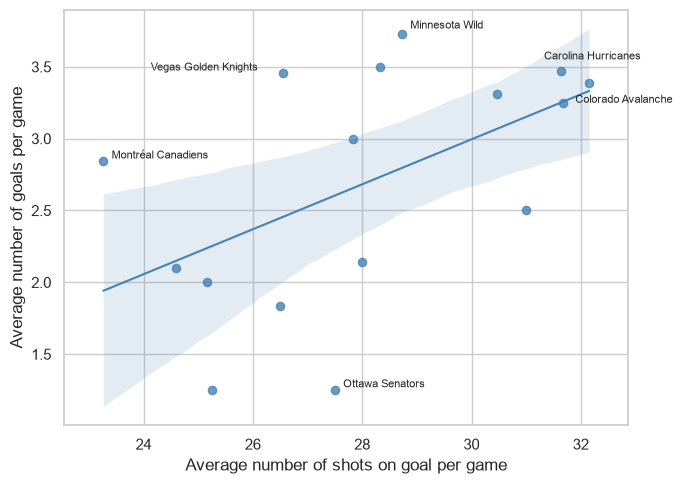

In [28]:
plt.figure(figsize=(7, 5))
ax = sns.regplot(data=avgshots, x='Shot', y='Goal', color='steelblue',
                 scatter_kws={'s': 35}, line_kws={'linewidth': 1.5}, seed=0)
ax.set_xlabel('Average number of shots on goal per game')
ax.set_ylabel('Average number of goals per game')

labelled = {'Carolina Hurricanes': (-12, 8), 'Colorado Avalanche': (-10, -14),
            'Minnesota Wild': (6, 4), 'Montréal Canadiens': (6, 2),
            'Ottawa Senators': (6, 2), 'Vegas Golden Knights': (-95, 2)}
for name, off in labelled.items():
   r = avgshots.loc[name]
   ax.annotate(name, (r['Shot'], r['Goal']), textcoords='offset points',
               xytext=off, fontsize=8)
ax.margins(x=0.08)
plt.tight_layout()
plt.savefig(FIG + '/shots_goals.pdf')
plt.savefig(FIG + '/shots_goals.png', dpi=160)
plt.show()

Облако вытянуто вправо, но вокруг прямой большой разброс и полоса широкая.
На глаз связь сомнительная, поэтому посчитаем её численно. Беру две корреляции:
Пирсона на случай линейной связи и Спирмена на случай монотонной нелинейной,
плюс t-статистику чтобы понять значимо ли это при 16 точках.

In [29]:
corr = avgshots['Shot'].corr(avgshots['Goal'])
spear = avgshots['Shot'].corr(avgshots['Goal'], method='spearman')
n = len(avgshots)
t = corr * np.sqrt((n - 2) / (1 - corr ** 2))

print('Пирсон  %.3f' % corr)
print('Спирмен %.3f' % spear)
print('t = %.3f, n = %d' % (t, n))

Пирсон  0.521
Спирмен 0.578
t = 2.283, n = 16


Связь положительная но слабая, R2 около 0.27. Формально значимо на 5 процентах,
но полоса на графике широкая. Монреаль бросает меньше всех и забивает выше линии,
Оттава наоборот. Само количество бросков результат почти не определяет, важнее откуда
бросают - к этому вернёмся в пункте 22.

### 14. Матч с наибольшим числом ударов

Считаем все попытки, включая промахи и заблокированные.

In [30]:
attempts = events[events['Play Type'].isin(shottypes + ['blocked-shot'])]
shotcount = attempts.groupby('Game ID').size()
idxmax = shotcount.idxmax()

print(gameInfo(idxmax), shotcount.max())
print()
print(shotcount.nlargest(5))

Carolina Hurricanes - Ottawa Senators (3 - 2, Final/2OT, 2026-04-20) 208

Game ID
2025030132    208
2025030164    169
2025030413    163
2025030126    156
2025030175    154
dtype: int64


208 попыток с большим отрывом, у следующего матча 169. игра шла
два овертайма.

### 15. Карта бросков

Нужно чтобы гости били влево а хозяева вправо. Развораиваем там где хозяева защищают
правые ворота. В условии предложено разворачивать нечётные периоды, для этого матча
это то же самое, через Defending Side правильно для любой игры.

Ещё момент: для blocked-shot поле Team Making the Play содержит команду бросавшего,
а не блокировавшего. Проверяется по координата - эти события лежат в зоне атаки.

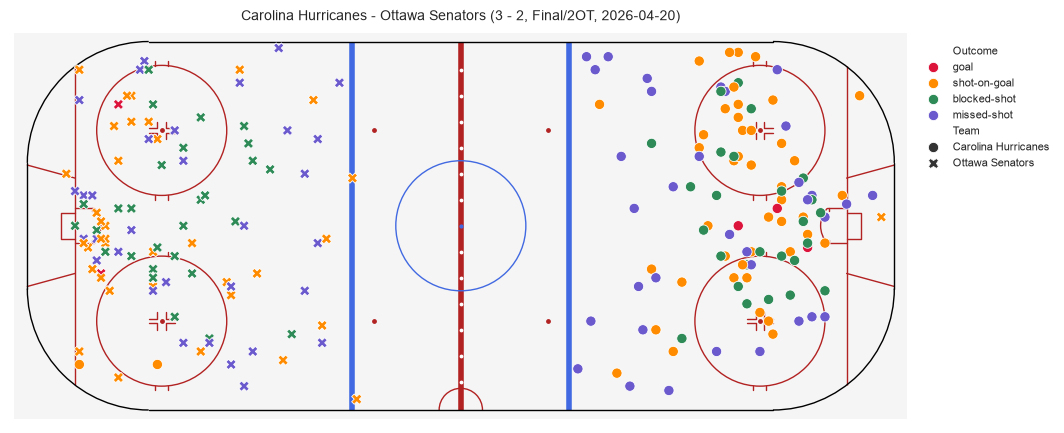

In [31]:
one = attempts[attempts['Game ID'] == idxmax].copy()
flip = np.where(one["Home Team's Defending Side"] == 'right', -1.0, 1.0)
one['X'] = one['X Coordinate on the Ice Rink'] * flip
one['Y'] = one['Y Coordinate on the Ice Rink'] * flip
one = one.rename(columns={'Play Type': 'Outcome', 'Team Making the Play': 'Team'})

plt.figure(figsize=(11, 4.2))
plot_rink()
sns.scatterplot(data=one, x='X', y='Y', hue='Outcome', style='Team', s=55,
                hue_order=['goal', 'shot-on-goal', 'blocked-shot', 'missed-shot'],
                palette=['crimson', 'darkorange', 'seagreen', 'slateblue'])
plt.xlim(-104, 104)
plt.ylim(-45.5, 45.5)
plt.gca().set_aspect('equal')
plt.axis('off')
plt.title(gameInfo(idxmax), fontsize=10)
plt.legend(bbox_to_anchor=(1.0, 0.98), loc='upper left', frameon=False, fontsize=8)
plt.tight_layout(pad=0.2)
plt.savefig(FIG + '/shotmap.pdf', bbox_inches='tight')
plt.savefig(FIG + '/shotmap.png', dpi=160, bbox_inches='tight')
plt.show()

Картинка выглядит правдоподобно: крестики Оттавы слева, кружки Каролины справа.
проверим числами - посчитаем распределение попыток
по исходам и средние координаты для каждой команды.

In [32]:
print(one.groupby(['Team', 'Outcome']).size().unstack(fill_value=0))
print()
print('гости бьют влево: ', one.loc[one['Team'] == one['Away Team'], 'X'].mean().round(2))
print('хозяева вправо:   ', one.loc[one['Team'] == one['Home Team'], 'X'].mean().round(2))

Outcome              blocked-shot  goal  missed-shot  shot-on-goal
Team                                                              
Carolina Hurricanes            26     3           34            46
Ottawa Senators                28     2           32            37

гости бьют влево:  -63.71
хозяева вправо:    61.26


Средние координаты разного знака, значит развернули правильно. На карте видно
плотное скопление перед воротами и россыпь неточных по краям зоны.

### 16. Снайперы

In [33]:
goals = events[events['Play Type'] == 'goal']
scorers = goals['Player in the Event #1'].value_counts()
scorers.head(10)

Player in the Event #1
Brett Howden        14
Pavel Dorofeyev     12
Logan Stankoven     11
Mitch Marner        10
Nikolaj Ehlers       8
Jordan Staal         8
Alex Newhook         7
Taylor Hall          7
Jackson Blake        7
Nathan MacKinnon     7
Name: count, dtype: int64

### 17. Ассистенты

Складываем передачи из двух полей.

In [34]:
assists = pd.concat([goals['Player in the Event #2'], goals['Player in the Event #3']]).dropna()
assists = assists.value_counts()
assists.head(10)

Jack Eichel        20
Mitch Marner       19
Lane Hutson        13
Jackson Blake      13
Nick Suzuki        12
Taylor Hall        12
Martin Necas       12
Shea Theodore      12
Kirill Kaprizov    11
Quinn Hughes       11
Name: count, dtype: int64

### 18. Очки гол плюс пас

In [35]:
points = scorers.add(assists, fill_value=0).astype(int).sort_values(ascending=False)
points.index.name = 'Player'

table = pd.DataFrame({'Goals': scorers.reindex(points.index).fillna(0).astype(int),
                      'Assists': assists.reindex(points.index).fillna(0).astype(int),
                      'Points': points})
table.head(10)

,Goals,Assists,Points
Player,,,
Mitch Marner,10,19,29
Jack Eichel,2,20,22
Jackson Blake,7,13,20
Taylor Hall,7,12,19
Brett Howden,14,4,18
Nikolaj Ehlers,8,10,18
Shea Theodore,6,12,18
Pavel Dorofeyev,12,4,16
Lane Hutson,3,13,16


Первые места у игроков Вегаса и Каролины, они сыграли 22 и 19 матчей против 4-6
у вылетевших в первом раунде. Так что это отчасти рейтинг длины пути по сетке.

### 19. Броски в створ за игру

Число матчей для игрока считаем по появлению на льду.

In [36]:
gp = onice.groupby('Player')['Game ID'].nunique()
shotsby = ongoal['Player in the Event #1'].value_counts()

pershot = pd.DataFrame({'Shots': shotsby, 'GP': gp.reindex(shotsby.index)})
pershot['Per Game'] = pershot['Shots'] / pershot['GP']
pershot.sort_values('Per Game', ascending=False).head(10)

,Shots,GP,Per Game
Player in the Event #1,,,
Jason Robertson,30,6,5.000
Dylan Guenther,27,6,4.500
Nikita Kucherov,31,7,4.429
Matt Boldy,48,11,4.364
Quinton Byfield,17,4,4.250
Darren Raddysh,28,7,4.000
Joel Eriksson Ek,24,6,4.000
Alex Laferriere,15,4,3.750
David Pastrnak,22,6,3.667


### 20. Силовые приёмы за игру

In [37]:
hitsby = events[events['Play Type'] == 'hit']['Player in the Event #1'].value_counts()

perhit = pd.DataFrame({'Hits': hitsby, 'GP': gp.reindex(hitsby.index)})
perhit['Per Game'] = perhit['Hits'] / perhit['GP']
perhit.sort_values('Per Game', ascending=False).head(10)

,Hits,GP,Per Game
Player in the Event #1,,,
Lawson Crouse,38,6,6.333
Alexander Petrovic,6,1,6.000
Alex Turcotte,6,1,6.000
Yakov Trenin,51,9,5.667
Dylan Cozens,22,4,5.500
Vasily Podkolzin,32,6,5.333
Ivan Barbashev,110,22,5.000
Carl Grundstrom,15,3,5.000
Marcus Foligno,55,11,5.000


Сюда попадают Turcotte и Petrovic с одним матчем и шестью приёмами. Формально
среднее 6.0, но не содержательно . Отсечём тех у кого меньше пяти игр.

In [38]:
perhit[perhit['GP'] >= 5].sort_values('Per Game', ascending=False).head(10)

,Hits,GP,Per Game
Player in the Event #1,,,
Lawson Crouse,38,6,6.333
Yakov Trenin,51,9,5.667
Vasily Podkolzin,32,6,5.333
Ivan Barbashev,110,22,5.000
Marcus Foligno,55,11,5.000
Owen Tippett,29,6,4.833
William Carrier,91,19,4.789
Colton Dach,23,5,4.600
Cole Smith,100,22,4.545


Так устойчивее. Барбашев держит пять приёмов за игру на дистанции 22 матчей.

### 21. Вратари на ноль

Гол пишем на того вратаря кто был на льду у пропускающей команды. Здесь и пригодились
awaygoalie / homegoalie с восстановленными овертаймами, иначе Dobes и Bussi получат
сухие матчи которых не было.

In [39]:
away = events[['Game ID', 'Away Team']].assign(Goalie=events["Away Team's Goalie"]).rename(columns={'Away Team': 'Team'})
home = events[['Game ID', 'Home Team']].assign(Goalie=events["Home Team's Goalie"]).rename(columns={'Home Team': 'Team'})
played = pd.concat([away, home]).dropna(subset=['Goalie']).drop_duplicates()

scoredbyhome = goals['Team Making the Play'] == goals['Home Team']
conceder = pd.Series(np.where(scoredbyhome, awaygoalie[goals.index], homegoalie[goals.index]), index=goals.index)
hit = conceder.dropna()
missed = hit.groupby([goals.loc[hit.index, 'Game ID'], hit]).size()

played = played.set_index(['Game ID', 'Goalie'])
played['GA'] = missed.reindex(played.index).fillna(0).astype(int)
shutouts = played[played['GA'] == 0].reset_index()

print('голов в пустые ворота:', conceder.isna().sum())
print('матчей на ноль:', len(shutouts))
shutouts.groupby(['Goalie', 'Team']).size().sort_values(ascending=False)

голов в пустые ворота: 3
матчей на ноль: 9


Goalie              Team               
Frederik Andersen   Carolina Hurricanes    3
Dan Vladar          Philadelphia Flyers    2
Andrei Vasilevskiy  Tampa Bay Lightning    1
Brandon Bussi       Carolina Hurricanes    1
Joonas Korpisalo    Boston Bruins          1
Scott Wedgewood     Colorado Avalanche     1
dtype: int64

Шесть вратарей, девять матчей. Больше всех у Андерсена - три.

Выведем эти матчи списком: по счёту сразу будет видно, где вратарь отыграл всю игру,
а вышел на замену.

In [41]:
shutouts.sort_values('Game ID')[['Goalie', 'Team']].assign(
    Game=[gameInfo(i) for i in shutouts.sort_values('Game ID')['Game ID']])

,Goalie,Team,Game
4,Joonas Korpisalo,Boston Bruins,"Boston Bruins - Buffalo Sabres (1 - 6, Final, ..."
0,Andrei Vasilevskiy,Tampa Bay Lightning,Montréal Canadiens - Tampa Bay Lightning (0 - ...
5,Frederik Andersen,Carolina Hurricanes,"Carolina Hurricanes - Ottawa Senators (2 - 0, ..."
1,Dan Vladar,Philadelphia Flyers,Pittsburgh Penguins - Philadelphia Flyers (0 -...
6,Dan Vladar,Philadelphia Flyers,Philadelphia Flyers - Pittsburgh Penguins (1 -...
7,Frederik Andersen,Carolina Hurricanes,Carolina Hurricanes - Philadelphia Flyers (3 -...
8,Scott Wedgewood,Colorado Avalanche,"Colorado Avalanche - Minnesota Wild (4 - 3, Fi..."
2,Frederik Andersen,Carolina Hurricanes,Montréal Canadiens - Carolina Hurricanes (0 - ...
3,Brandon Bussi,Carolina Hurricanes,Vegas Golden Knights - Carolina Hurricanes (0 ...


Два случая это замены по ходу матча. Korpisalo вышел в третьем периоде при 1:6,
все шесть пропустил Swayman. Wedgewood заменил Blackwood после трёх пропущенных
в первом периоде и отыграл остаток насухо.

Контроль: сумма пропущенных по всем парам вратарь-матч должна равняться 486 минус
3 гола в пустые ворота.

In [40]:
played['GA'].sum()

np.int64(483)

### 22. Свой вопрос: насколько опасен бросок с разной дистанции

В пункте 13 связь количества бросков с голами оказалась слабой. Логично проверить
что дело в качестве моментов, а расстояние это простейшая мера качества.

In [42]:
sh = shots.copy()
sh['Goal'] = (sh['Play Type'] == 'goal').astype(int)
sh['Lead'] = np.where(sh['Team Making the Play'] == sh['Home Team'],
                      sh['Cumulated Home Score'] - sh['Cumulated Away Score'],
                      sh['Cumulated Away Score'] - sh['Cumulated Home Score'])
sh['Left'] = sh['Remaining Time'].str.split(':').apply(lambda t: int(t[0]) * 60 + int(t[1]))
sh['Endgame'] = (sh['Period'] >= 3) & (sh['Left'] <= 180) & (sh['Lead'] >= 1)

bins = [0, 10, 20, 30, 40, 50, 60, 100, 200]
labels = ['0-10', '10-20', '20-30', '30-40', '40-50', '50-60', '60-100', '100+']
sh['Zone'] = pd.cut(sh['Shot Length'], bins=bins, labels=labels, right=False)

conv = sh.groupby('Zone', observed=True).agg(Shots=('Goal', 'size'), Goals=('Goal', 'sum'))
conv['Conversion'] = conv['Goals'] / conv['Shots']
conv['On Goal Share'] = sh.groupby('Zone', observed=True)['Play Type'].apply(lambda s: (s != 'missed-shot').mean())
conv

,Shots,Goals,Conversion,On Goal Share
Zone,,,,
0-10,1137,134,0.118,0.676
10-20,1136,113,0.099,0.613
20-30,1132,96,0.085,0.619
30-40,1244,69,0.055,0.671
40-50,976,26,0.027,0.623
50-60,764,19,0.025,0.546
60-100,694,12,0.017,0.630
100+,183,17,0.093,0.874


Падение резкое: с пятачка забивается примерно каждый девятый бросок, дальше
60 футов меньше двух процентов. При этом доля попаданий в створ держится около 0.6
и от расстояния почти не зависит. То есть расстояние влияет не на точность, а на то
справится ли вратарь.

Выбивается последняя группа - 9.3 процента, почти как с пятачка. Это те самые пустые
ворота из пункта 9. Уберём концовки третьего периода при ведении в счёте.

In [43]:
guarded = sh[~sh['Endgame']]
conv2 = guarded.groupby('Zone', observed=True).agg(Shots=('Goal', 'size'), Goals=('Goal', 'sum'))
conv2['Conversion'] = conv2['Goals'] / conv2['Shots']

print(conv2)
print()
print('таких бросков:', int(sh['Endgame'].sum()), 'из них голов:', int(sh.loc[sh['Endgame'], 'Goal'].sum()))
print('их реализация: %.3f против %.3f у остальных' % (sh.loc[sh['Endgame'], 'Goal'].mean(), sh.loc[~sh['Endgame'], 'Goal'].mean()))

        Shots  Goals  Conversion
Zone                            
0-10     1130    132       0.117
10-20    1123    105       0.093
20-30    1127     94       0.083
30-40    1235     65       0.053
40-50     972     24       0.025
50-60     755     15       0.020
60-100    679     10       0.015
100+      152      3       0.020

таких бросков: 93 из них голов: 38
их реализация: 0.409 против 0.062 у остальных


Последняя группа упала с 0.093 до 0.020 и зависимость стала монотонной.
Нарисуем оба варианта рядом, чтобы разица была видна глазом. Общую ось y ставлю
через sharey, иначе столбцы будут в разных масштабах и сравнивать их нельзя.

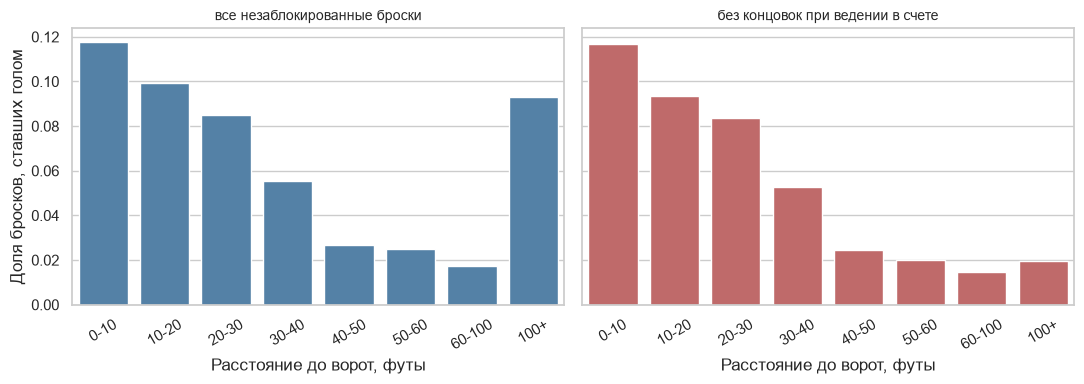

In [44]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
sns.barplot(x=conv.index, y=conv['Conversion'], color='steelblue', ax=axes[0])
axes[0].set_title('все незаблокированные броски', fontsize=10)
axes[0].set_xlabel('Расстояние до ворот, футы')
axes[0].set_ylabel('Доля бросков, ставших голом')
sns.barplot(x=conv2.index, y=conv2['Conversion'], color='indianred', ax=axes[1])
axes[1].set_title('без концовок при ведении в счете', fontsize=10)
axes[1].set_xlabel('Расстояние до ворот, футы')
axes[1].set_ylabel('')
for a in axes:
     a.tick_params(axis='x', labelrotation=30)
plt.tight_layout()
plt.savefig(FIG + '/conversion.pdf')
plt.savefig(FIG + '/conversion.png', dpi=160)
plt.show()

Аномалия ушла, зависимость стала строго монотонной. Концовочных бросков всего 93
но они дали 38 голов. Меньше 1.3 процента бросков турнира принесли почти 8 процентов
голов.

Отсюда понятно и почему в пункте 13 связь была слабой - броски неравноценны, и команда
бросающая много но издалека вполне может уступать по голам той кто бросает реже
но из опасных зон.

Попутно посмотрел преимущество своего поля.

In [45]:
homewin = (games['Home Score'] > games['Away Score'])
reg = games['Outcome'] == 'Final'

print('побед хозяев: %d из %d (%.3f)' % (homewin.sum(), len(games), homewin.mean()))
print('в основное время: %d из %d (%.3f)' % ((homewin & reg).sum(), reg.sum(), homewin[reg].mean()))
print('в овертаймах:     %d из %d (%.3f)' % ((homewin & ~reg).sum(), (~reg).sum(), homewin[~reg].mean()))
print('z = %.3f' % ((homewin.mean() - 0.5) / np.sqrt(0.25 / len(games))))

побед хозяев: 39 из 82 (0.476)
в основное время: 25 из 60 (0.417)
в овертаймах:     14 из 22 (0.636)
z = -0.442


Никакого преимущества в этом плей-офф не было, 47.6 процента, отклонение
незначимо. Зато в овертаймах хозяева взяли 14 из 22. Выборка маленькая, но правом
последней смены это объясняется правдоподобно.